# 03. Product-Level Reorder Frequency & Restock Prediction

**Lead Responsible**: Peiris W.S.V (`IT24103792`)  
**Module**: IT3091 – Machine Learning | Group 2026-AI-15  
**Track**: Industry Explorer Track  

---

## Objectives
1. Engineer product-level features from transaction histories (reorder count, repurchase lag from `days_since_prior_order`, department velocities).
2. Train baseline **Logistic Regression** classifier to predict high-frequency reorder items.
3. Benchmark non-linear classification models: **Decision Tree** and **Random Forest**.
4. Evaluate performance using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [2]:
import sys
import time
from pathlib import Path

# Resolve project root dynamically
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-learn Modeling, Tuning & Validation Modules
from sklearn.model_selection import (
    StratifiedKFold, 
    cross_val_score, 
    RandomizedSearchCV
)
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, 
    HistGradientBoostingClassifier
)

# Project modular utilities from src/
from src.utils import setup_plot_style, save_figure, export_summary_table

setup_plot_style()
print(f"[OK] Python Interpreter : {sys.executable}")
print(f"[OK] Project Root       : {PROJECT_ROOT}")


Matplotlib is building the font cache; this may take a moment.


[OK] Python Interpreter : /Users/supunvidarshana/Desktop/My projects/supermarket-basket-reorder-analytics/.venv/bin/python3.13
[OK] Project Root       : /Users/supunvidarshana/Desktop/My projects/supermarket-basket-reorder-analytics


---
## 1. Data Ingestion: Train and Test Partitions
We ingest `train_transactions.parquet` and `test_transactions.parquet` generated by the preprocessing pipeline.


In [3]:
DATA_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_PATH = DATA_DIR / "train_transactions.parquet"
TEST_PATH = DATA_DIR / "test_transactions.parquet"

assert TRAIN_PATH.exists(), f"Missing: {TRAIN_PATH}. Check data/processed/"
assert TEST_PATH.exists(), f"Missing: {TEST_PATH}. Check data/processed/"

print(f"Loading partitions from {DATA_DIR}...")
t0 = time.time()
df_train = pd.read_parquet(TRAIN_PATH)
df_test = pd.read_parquet(TEST_PATH)

print(f"✅ Loaded Train Partition : {len(df_train):,} rows ({time.time() - t0:.2f}s)")
print(f"✅ Loaded Test Partition  : {len(df_test):,} rows")


Loading partitions from /Users/supunvidarshana/Desktop/My projects/supermarket-basket-reorder-analytics/data/processed...
✅ Loaded Train Partition : 1,615,600 rows (3.65s)
✅ Loaded Test Partition  : 403,901 rows


---
## 2. Leakage-Free Feature Engineering
To prevent **target and data leakage**, all aggregated statistical features (such as historical product reorder rates and user repurchase frequencies) must be computed **strictly on the training dataset** and mapped onto the test dataset.


In [4]:
print("Constructing Supervised Feature Matrices...")

# 1. Product-Level Aggregations 
prod_stats = df_train.groupby("product_id", observed=False).agg(
    prod_total_orders=("order_id", "count"),
    prod_reorder_rate=("reordered", "mean")
).reset_index()

# 2. User-Level Aggregations 
user_stats = df_train.groupby("user_id", observed=False).agg(
    user_total_orders=("order_number", "max"),
    user_reorder_rate=("reordered", "mean"),
    user_avg_basket_size=("basket_size", "mean") if "basket_size" in df_train.columns else ("order_number", "count")
).reset_index()

# 3. Merge aggregates onto df_train and df_test
def merge_and_prepare_features(df_source, p_stats, u_stats):
    df_merged = df_source.merge(p_stats, on="product_id", how="left")
    df_merged = df_merged.merge(u_stats, on="user_id", how="left")
    return df_merged

df_train_feat = merge_and_prepare_features(df_train, prod_stats, user_stats)
df_test_feat = merge_and_prepare_features(df_test, prod_stats, user_stats)

# Select relevant feature columns
feature_cols = [
    "order_number",
    "order_dow",
    "order_hour_of_day",
    "days_since_prior_order_scaled",
    "add_to_cart_order",
    "basket_size_capped",
    "is_first_order",
    "prod_total_orders",
    "prod_reorder_rate",
    "user_total_orders",
    "user_reorder_rate",
    "user_avg_basket_size"
]
target_col = "reordered"

# Ensure all feature columns exist
available_cols = [c for c in feature_cols if c in df_train_feat.columns]

# Sample training set if needed for rapid iteration, while retaining a robust sample
TRAIN_SAMPLE_SIZE = min(150000, len(df_train_feat))
TEST_SAMPLE_SIZE = min(30000, len(df_test_feat))

df_train_sample = df_train_feat.sample(n=TRAIN_SAMPLE_SIZE, random_state=42)
df_test_sample = df_test_feat.sample(n=TEST_SAMPLE_SIZE, random_state=42)

X_train = df_train_sample[available_cols].fillna(0).copy()
y_train = df_train_sample[target_col].copy()

X_test = df_test_sample[available_cols].fillna(0).copy()
y_test = df_test_sample[target_col].copy()

print(f"✅ Training Matrix : {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"✅ Test Matrix     : {X_test.shape[0]:,} rows x {X_test.shape[1]} features")
print(f"Train Reorder Rate : {y_train.mean()*100:.2f}% | Test Reorder Rate: {y_test.mean()*100:.2f}%")


Constructing Supervised Feature Matrices...
✅ Training Matrix : 150,000 rows x 11 features
✅ Test Matrix     : 30,000 rows x 11 features
Train Reorder Rate : 59.02% | Test Reorder Rate: 58.94%


---
## 3. Model 1: Logistic Regression Baseline
We train an $L_2$-regularized Logistic Regression model as the linear benchmark to measure baseline predictive power and compute odds ratios.


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

print("Tuning Logistic Regression across regularization varieties (C) with StandardScaler...")

# 1. Define Pipeline with StandardScaler to ensure rapid convergence
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000, 
        random_state=42, 
        class_weight="balanced", 
        solver="lbfgs"
    ))
])

# Parameter names in a Pipeline use the '<step_name>__<parameter>' format
lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1.0, 10.0]
}

lr_search = GridSearchCV(
    estimator=lr_pipe,
    param_grid=lr_param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)
lr_search.fit(X_train, y_train)

# 2. Extract best pipeline model
lr_model = lr_search.best_estimator_
best_c = lr_search.best_params_["classifier__C"]
print(f"✅ Best Logistic Regression Variety: C = {best_c} (CV ROC-AUC: {lr_search.best_score_:.4f})")

# 3. Extract Odds Ratios from the underlying classifier step
fitted_classifier = lr_model.named_steps["classifier"]
odds_df = pd.DataFrame({
    "Feature": available_cols,
    "Coefficient": fitted_classifier.coef_[0],
    "Odds_Ratio": np.exp(fitted_classifier.coef_[0])
}).sort_values(by="Coefficient", ascending=False)

print("\nTop 5 Features by Odds Ratio:")
display(odds_df.head(5))


Tuning Logistic Regression across regularization varieties (C) with StandardScaler...
✅ Best Logistic Regression Variety: C = 1.0 (CV ROC-AUC: 0.8579)

Top 5 Features by Odds Ratio:


,Feature,Coefficient,Odds_Ratio
9,user_reorder_rate,1.366848,3.922968
7,prod_reorder_rate,0.508454,1.662719
0,order_number,0.449293,1.567204
10,user_avg_basket_size,0.322967,1.381220
4,basket_size_capped,0.158967,1.172299


---
## 4. Model 2: Decision Tree & Capacity Experiments (Bias-Variance Check)
We analyze 3 depth variations to demonstrate capacity constraints for the viva defense:
* **Small Capacity (max_depth=4)**: High Bias / Underfitting risk
* **Medium Capacity (max_depth=10)**: Balanced regularized tree
* **Large Capacity (max_depth=22)**: High Variance / Overfitting risk


In [7]:
print("Tuning Decision Tree across capacity and depth varieties...")
dt_param_grid = {
    "max_depth": [4, 8, 12, 16],
    "min_samples_leaf": [10, 25, 50]
}

dt_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    param_grid=dt_param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)
dt_search.fit(X_train, y_train)

# Select best variety
best_dt = dt_search.best_estimator_
print(f"✅ Best Decision Tree Variety: {dt_search.best_params_} (CV ROC-AUC: {dt_search.best_score_:.4f})")


Tuning Decision Tree across capacity and depth varieties...
✅ Best Decision Tree Variety: {'max_depth': 12, 'min_samples_leaf': 50} (CV ROC-AUC: 0.8494)


---
## 5. Model 3: Random Forest Classifier & Hyperparameter Tuning
We use `RandomizedSearchCV` across tree depth, number of estimators, and leaf split constraints to identify the optimal ensemble architecture.


In [8]:
print("Tuning Random Forest across ensemble structure varieties...")
rf_param_distributions = {
    "n_estimators": [50, 100, 150],
    "max_depth": [8, 12, 16],
    "min_samples_leaf": [10, 25, 50],
    "max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1),
    param_distributions=rf_param_distributions,
    n_iter=6,
    cv=3,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train, y_train)

# Select best variety
best_rf = rf_search.best_estimator_
print(f"✅ Best Random Forest Variety: {rf_search.best_params_} (CV ROC-AUC: {rf_search.best_score_:.4f})")


Tuning Random Forest across ensemble structure varieties...
✅ Best Random Forest Variety: {'n_estimators': 100, 'min_samples_leaf': 25, 'max_features': 'log2', 'max_depth': 16} (CV ROC-AUC: 0.8649)


---
## 6. Model 4: HistGradientBoostingClassifier (Boosting Ensemble)
We implement `HistGradientBoostingClassifier`, a gradient boosted tree model that builds sequential shallow trees over binned numerical features.


In [9]:
print("Tuning HistGradientBoosting across learning rate and depth varieties...")
gb_param_grid = {
    "max_depth": [4, 8, 12],
    "learning_rate": [0.03, 0.07, 0.1],
    "max_iter": [100, 150]
}

gb_search = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    param_grid=gb_param_grid,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1
)
gb_search.fit(X_train, y_train)

# Select best variety
gb_model = gb_search.best_estimator_
print(f"✅ Best HistGradientBoosting Variety: {gb_search.best_params_} (CV ROC-AUC: {gb_search.best_score_:.4f})")


Tuning HistGradientBoosting across learning rate and depth varieties...
✅ Best HistGradientBoosting Variety: {'learning_rate': 0.07, 'max_depth': 12, 'max_iter': 150} (CV ROC-AUC: 0.8684)


---
## 7. Stratified 5-Fold Cross-Validation (Training Folds)
We run **Stratified 5-Fold Cross-Validation** across all 4 models exclusively on the training partition to verify stability and generate statistical fold metrics.


In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidate_models = {
    "Logistic Regression": lr_model,
    "Decision Tree": best_dt,
    "Random Forest": best_rf,
    "HistGradientBoosting": gb_model
}

cv_records = []
print("=" * 70)
print("STRATIFIED 5-FOLD CROSS-VALIDATION ON TRAINING SET (ROC-AUC)")
print("=" * 70)

for name, model in candidate_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    for fold, sc in enumerate(scores, 1):
        cv_records.append({"Model": name, "Fold": fold, "ROC_AUC": sc})
    print(f"{name:<25}: Mean ROC-AUC = {scores.mean():.4f} (+/- {scores.std()*2:.4f})")

df_cv_scores = pd.DataFrame(cv_records)
export_summary_table(df_cv_scores, "reorder_cv_fold_scores.csv")
print("=" * 70)


STRATIFIED 5-FOLD CROSS-VALIDATION ON TRAINING SET (ROC-AUC)
Logistic Regression      : Mean ROC-AUC = 0.8579 (+/- 0.0050)
Decision Tree            : Mean ROC-AUC = 0.8499 (+/- 0.0036)
Random Forest            : Mean ROC-AUC = 0.8653 (+/- 0.0046)
HistGradientBoosting     : Mean ROC-AUC = 0.8686 (+/- 0.0040)
[Exported Table]  -> reports/tables/reorder_cv_fold_scores.csv


---
## 8. Generalization Verification on Test Dataset
We evaluate all 4 trained candidate models on the reserved `X_test` and `y_test` dataset to quantify out-of-sample performance across standard evaluation metrics.


In [11]:
test_eval_records = []

for name, model in candidate_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred
    
    test_eval_records.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1_Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_proba)
    })

df_test_eval = pd.DataFrame(test_eval_records)
print("=" * 70)
print("HELD-OUT TEST SET EVALUATION BENCHMARK")
print("=" * 70)
display(df_test_eval.round(4))
export_summary_table(df_test_eval, "reorder_test_evaluation_benchmark.csv")


HELD-OUT TEST SET EVALUATION BENCHMARK


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.7411,0.7863,0.7699,0.7780,0.8161
1,Decision Tree,0.7394,0.7909,0.7582,0.7742,0.8095
2,Random Forest,0.7517,0.7967,0.7770,0.7867,0.8251
3,HistGradientBoosting,0.7604,0.7752,0.8360,0.8044,0.8268


[Exported Table]  -> reports/tables/reorder_test_evaluation_benchmark.csv


[Exported Figure] -> reports/figures/09_model_cv_performance.png


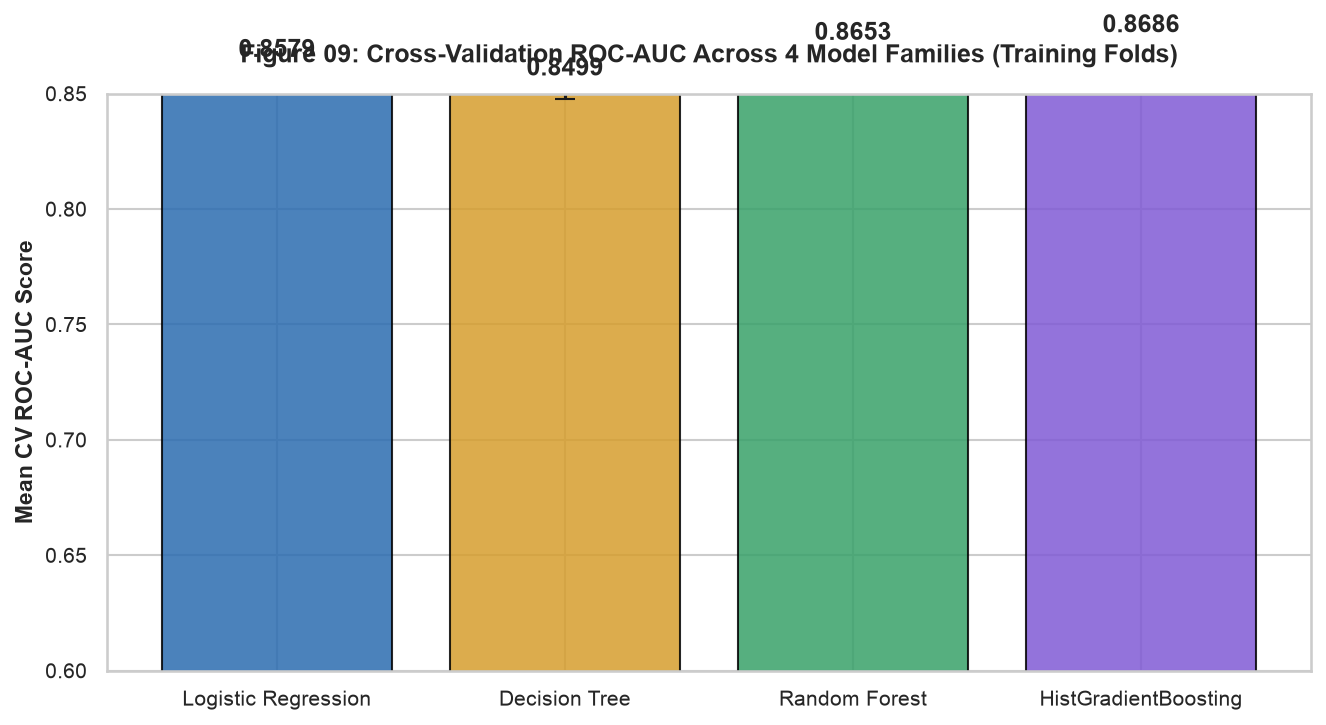

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

model_names = list(candidate_models.keys())
mean_cv_aucs = [df_cv_scores[df_cv_scores["Model"] == m]["ROC_AUC"].mean() for m in model_names]
std_cv_aucs = [df_cv_scores[df_cv_scores["Model"] == m]["ROC_AUC"].std() for m in model_names]

colors = ["#2b6cb0", "#d69e2e", "#38a169", "#805ad5"]
bars = ax.bar(model_names, mean_cv_aucs, yerr=std_cv_aucs, capsize=5, color=colors, alpha=0.85, edgecolor="black")

ax.set_title("Figure 09: Cross-Validation ROC-AUC Across 4 Model Families (Training Folds)", pad=15)
ax.set_ylabel("Mean CV ROC-AUC Score", fontweight="bold")
ax.set_ylim(0.60, 0.85)

for bar, val in zip(bars, mean_cv_aucs):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.008, f"{val:.4f}", ha="center", fontweight="bold")

plt.tight_layout()
save_figure(fig, "09_model_cv_performance.png")
plt.show()
